In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

df = pd.read_csv(r'C:\Users\tchin\Downloads\tchin-covid-sir-model\data\raw\total_cases.csv')
df['date'] = pd.to_datetime(df['date'])

df

,date,World,Afghanistan,Africa,Albania,Algeria,American Samoa,Andorra,Angola,Anguilla,...,Uruguay,Uzbekistan,Vanuatu,Vatican,Venezuela,Vietnam,Wallis and Futuna,Yemen,Zambia,Zimbabwe
0,2020-01-05,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2020-01-06,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2020-01-07,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2020-01-08,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2020-01-09,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1669,2024-07-31,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1670,2024-08-01,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1671,2024-08-02,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1672,2024-08-03,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386


In [5]:
def sir_model(t, y, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

sol = solve_ivp(sir_model, (0, 160), [0.99, 0.01, 0], args=(0.3, 0.1), t_eval=np.linspace(0, 160, 160))
sol_df = pd.DataFrame(sol.y.T, columns=['S', 'I', 'R'])

sol_df

,S,I,R
0,0.990000,0.010000,0.000000
1,0.986701,0.012187,0.001113
2,0.982697,0.014835,0.002468
3,0.977849,0.018034,0.004117
4,0.971991,0.021890,0.006120
...,...,...,...
155,0.058304,0.000015,0.941681
156,0.058304,0.000014,0.941682
157,0.058303,0.000013,0.941683
158,0.058303,0.000012,0.941685


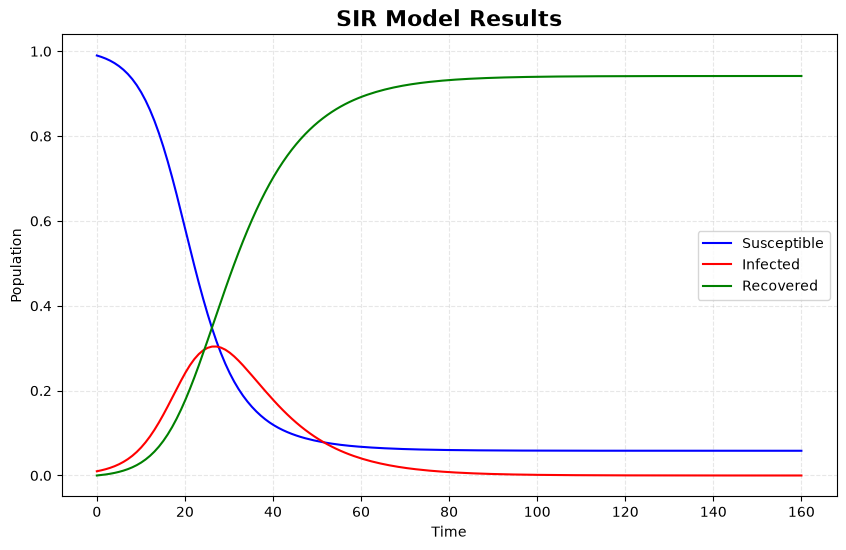

In [23]:
# Plot global SIR model results
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol_df['S'], label='Susceptible', color='blue')
plt.plot(sol.t, sol_df['I'], label='Infected', color='red')
plt.plot(sol.t, sol_df['R'], label='Recovered', color='green')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('SIR Model Results', fontsize=16, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()